In [1]:

!pip install -q gdown

import gdown
import pandas as pd

file_id = "19DvFNm3LlvvqRyTD5A8HX6Wpvn7GiKcY"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "linear_regression_dataset.csv", quiet=False)

df = pd.read_csv("linear_regression_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Downloading...
From: https://drive.google.com/uc?id=19DvFNm3LlvvqRyTD5A8HX6Wpvn7GiKcY
To: /content/linear_regression_dataset.csv
Downloading...
From: https://drive.google.com/uc?id=19DvFNm3LlvvqRyTD5A8HX6Wpvn7GiKcY
To: /content/linear_regression_dataset.csv
100%|██████████| 2.17k/2.17k [00:00<00:00, 1.39MB/s]

Dataset Shape: (100, 5)

First 5 Rows:
Dataset Shape: (100, 5)

First 5 Rows:


,area_sqft,bedrooms,age_years,distance_to_city_km,price_lakh
0,685,2,1,2.3,54.01
1,720,3,2,3.1,53.91
2,755,4,3,3.9,62.52
3,790,1,4,4.7,44.52
4,825,2,5,5.5,53.42



Column Names:
['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km', 'price_lakh']


,area_sqft,bedrooms,age_years,distance_to_city_km,price_lakh
0,685,2,1,2.3,54.01
1,720,3,2,3.1,53.91
2,755,4,3,3.9,62.52
3,790,1,4,4.7,44.52
4,825,2,5,5.5,53.42



Column Names:
['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km', 'price_lakh']


In [2]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_sqft            100 non-null    int64  
 1   bedrooms             100 non-null    int64  
 2   age_years            100 non-null    int64  
 3   distance_to_city_km  100 non-null    float64
 4   price_lakh           100 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 4.0 KB

Missing Values:
area_sqft              0
bedrooms               0
age_years              0
distance_to_city_km    0
price_lakh             0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,area_sqft,bedrooms,age_years,distance_to_city_km,price_lakh
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,1562.700000,2.500000,12.000000,12.380000,76.519100
std,523.246673,1.123666,7.247431,6.988128,23.635866
min,685.000000,1.000000,0.000000,1.500000,31.630000
25%,1114.500000,1.750000,6.000000,6.300000,56.865000
50%,1561.500000,2.500000,12.000000,11.900000,74.925000
75%,2008.500000,3.250000,18.000000,18.300000,97.070000
max,2473.000000,4.000000,24.000000,24.700000,122.560000


In [3]:
from sklearn.model_selection import train_test_split

# Input features and target
X = df[['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km']]
y = df['price_lakh']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (80, 4)
Testing Data Shape: (20, 4)

Training Target Shape: (80,)
Testing Target Shape: (20,)


In [4]:
from sklearn.linear_model import LinearRegression

# Select only area_sqft
X_simple_train = X_train[['area_sqft']]
X_simple_test = X_test[['area_sqft']]

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)

# Predict house prices
y_pred_simple = simple_model.predict(X_simple_test)

# Display model information
print("Simple Linear Regression")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

print("\nFirst 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_simple[:10])

Simple Linear Regression
Intercept: 10.897174959569583
Coefficient: 0.04153535031375136

First 10 Actual Prices:
[ 78.44  43.22  79.48 101.94 101.63  92.21  67.69  87.92  66.99  54.01]

First 10 Predicted Prices:
[ 91.30961317  46.20222273  71.91260457 106.76076348 105.30702622
  98.03833992  72.32795807  86.94840138  54.38468674  39.34888992]


In [5]:
from sklearn.linear_model import LinearRegression

# Create Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the model using all four features
multiple_model.fit(X_train, y_train)

# Predict house prices
y_pred_multiple = multiple_model.predict(X_test)

# Display model information
print("Multiple Linear Regression")
print("Intercept:", multiple_model.intercept_)

print("\nFeature Coefficients:")
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(f"{feature}: {coefficient}")

print("\nFirst 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_multiple[:10])

Multiple Linear Regression
Intercept: 9.624612475462115

Feature Coefficients:
area_sqft: 0.04512281269570456
bedrooms: 5.853596181681816
age_years: -0.6347373339676601
distance_to_city_km: -0.8723231105811586

First 10 Actual Prices:
[ 78.44  43.22  79.48 101.94 101.63  92.21  67.69  87.92  66.99  54.01]

First 10 Predicted Prices:
[ 79.06624964  44.94375409  77.009997   105.52514823  99.42484942
  92.33774013  67.8174486   84.17973796  64.31554338  49.59985105]


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Simple Linear Regression metrics
simple_mae = mean_absolute_error(y_test, y_pred_simple)
simple_mse = mean_squared_error(y_test, y_pred_simple)
simple_rmse = np.sqrt(simple_mse)
simple_r2 = r2_score(y_test, y_pred_simple)

# Multiple Linear Regression metrics
multiple_mae = mean_absolute_error(y_test, y_pred_multiple)
multiple_mse = mean_squared_error(y_test, y_pred_multiple)
multiple_rmse = np.sqrt(multiple_mse)
multiple_r2 = r2_score(y_test, y_pred_multiple)

# Display comparison
print("MODEL PERFORMANCE COMPARISON")
print("-" * 65)

print(f"{'Metric':<15}{'Simple LR':<20}{'Multiple LR':<20}")
print("-" * 65)

print(f"{'MAE':<15}{simple_mae:<20.4f}{multiple_mae:<20.4f}")
print(f"{'MSE':<15}{simple_mse:<20.4f}{multiple_mse:<20.4f}")
print(f"{'RMSE':<15}{simple_rmse:<20.4f}{multiple_rmse:<20.4f}")
print(f"{'R2 Score':<15}{simple_r2:<20.4f}{multiple_r2:<20.4f}")

MODEL PERFORMANCE COMPARISON
-----------------------------------------------------------------
Metric         Simple LR           Multiple LR         
-----------------------------------------------------------------
MAE            7.9404              1.9309              
MSE            104.0444            5.1520              
RMSE           10.2002             2.2698              
R2 Score       0.7526              0.9877              


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


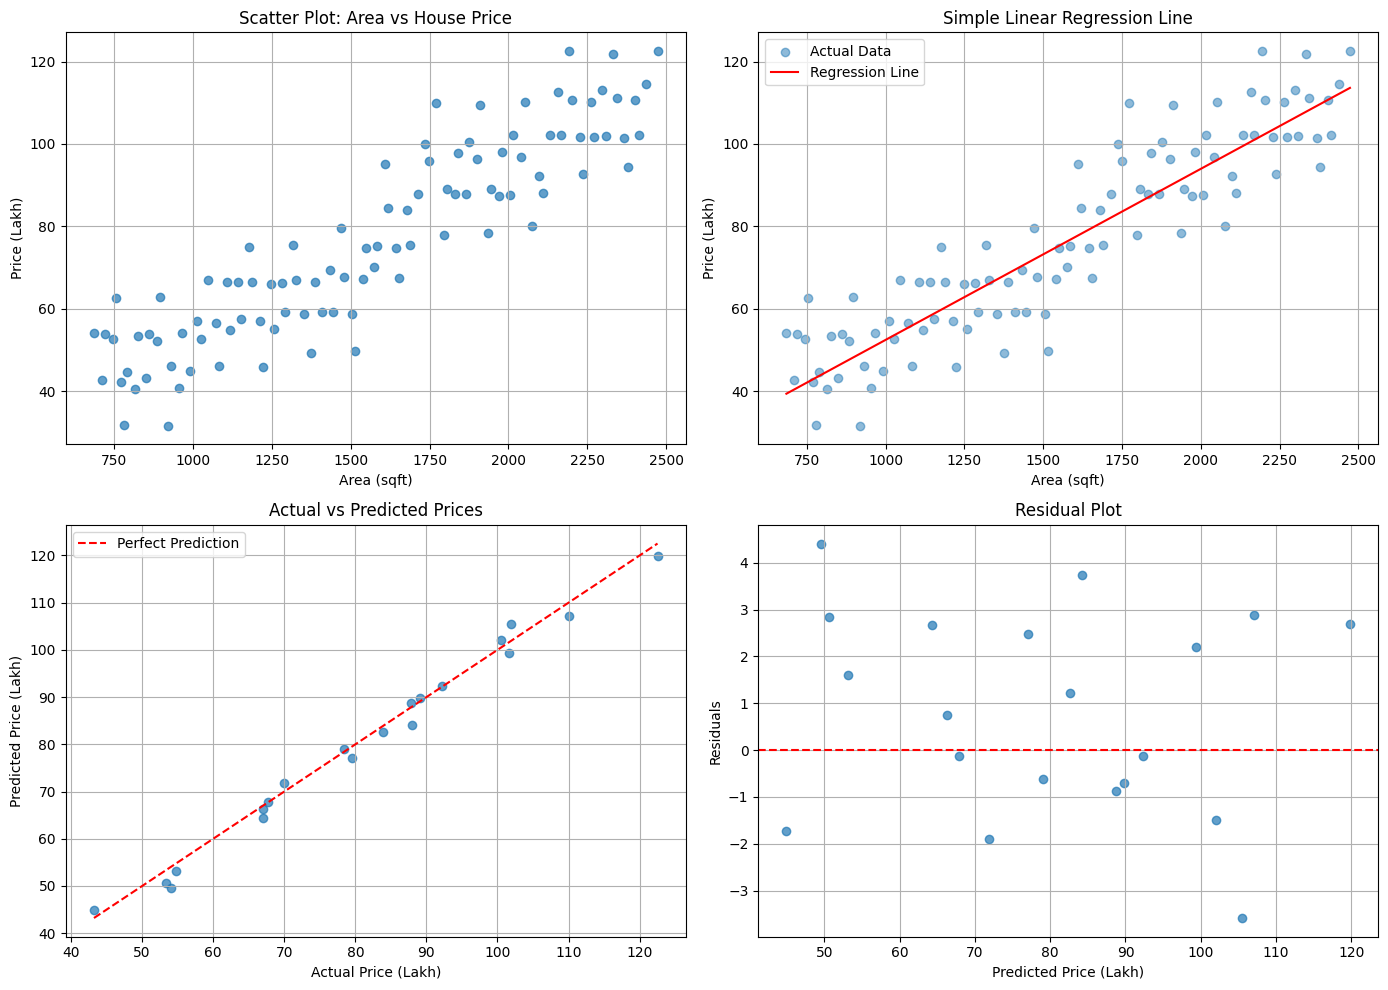

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 10))

# 1. Scatter Plot: Area vs Price
plt.subplot(2, 2, 1)
plt.scatter(df['area_sqft'], df['price_lakh'], alpha=0.7)
plt.xlabel('Area (sqft)')
plt.ylabel('Price (Lakh)')
plt.title('Scatter Plot: Area vs House Price')
plt.grid(True)

# 2. Regression Line: Simple Linear Regression
plt.subplot(2, 2, 2)

x_line = np.linspace(
    df['area_sqft'].min(),
    df['area_sqft'].max(),
    100
).reshape(-1, 1)

y_line = simple_model.predict(x_line)

plt.scatter(df['area_sqft'], df['price_lakh'], alpha=0.5, label='Actual Data')
plt.plot(x_line, y_line, color='red', label='Regression Line')
plt.xlabel('Area (sqft)')
plt.ylabel('Price (Lakh)')
plt.title('Simple Linear Regression Line')
plt.legend()
plt.grid(True)

# 3. Actual vs Predicted: Multiple Linear Regression
plt.subplot(2, 2, 3)

plt.scatter(y_test, y_pred_multiple, alpha=0.7)

min_val = min(y_test.min(), y_pred_multiple.min())
max_val = max(y_test.max(), y_pred_multiple.max())

plt.plot([min_val, max_val], [min_val, max_val],
         color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('Actual Price (Lakh)')
plt.ylabel('Predicted Price (Lakh)')
plt.title('Actual vs Predicted Prices')
plt.legend()
plt.grid(True)

# 4. Residual Plot: Multiple Linear Regression
residuals = y_test - y_pred_multiple

plt.subplot(2, 2, 4)
plt.scatter(y_pred_multiple, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Price (Lakh)')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True)

plt.tight_layout()
plt.show()

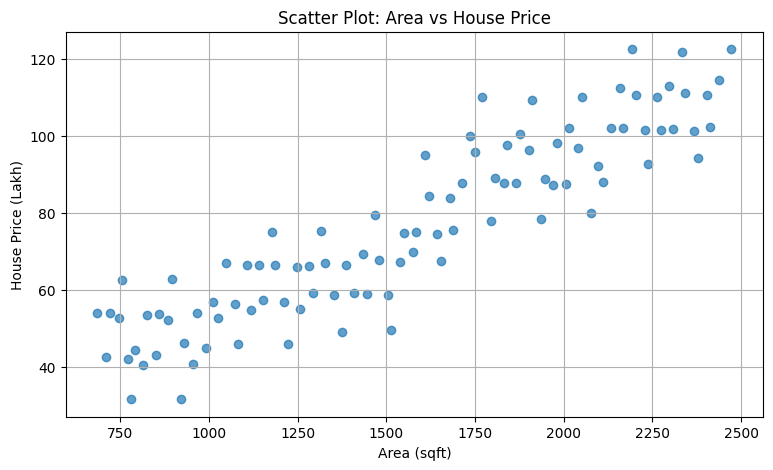

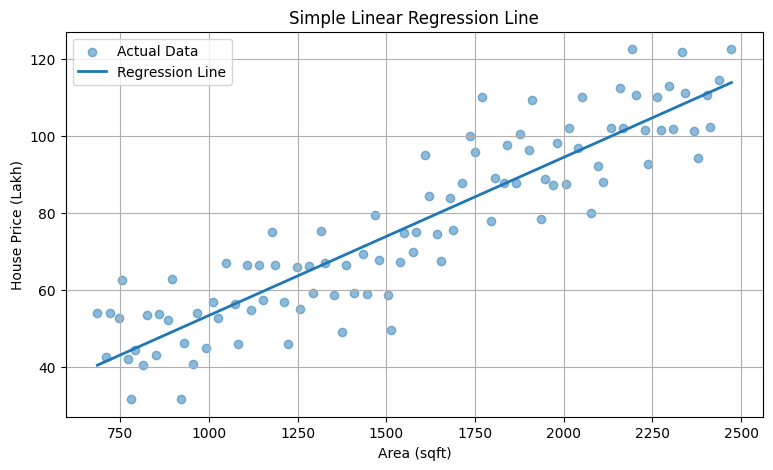

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare area data
X_area = df[['area_sqft']]
y_price = df['price_lakh']

# Train a simple model on the complete dataset for visualization
visual_model = LinearRegression()
visual_model.fit(X_area, y_price)

# Generate predictions for regression line
area_range = pd.DataFrame({
    'area_sqft': np.linspace(
        df['area_sqft'].min(),
        df['area_sqft'].max(),
        100
    )
})

price_line = visual_model.predict(area_range)

# Scatter Plot
plt.figure(figsize=(9, 5))
plt.scatter(
    df['area_sqft'],
    df['price_lakh'],
    alpha=0.7
)
plt.xlabel('Area (sqft)')
plt.ylabel('House Price (Lakh)')
plt.title('Scatter Plot: Area vs House Price')
plt.grid(True)
plt.show()

# Regression Line Plot
plt.figure(figsize=(9, 5))
plt.scatter(
    df['area_sqft'],
    df['price_lakh'],
    alpha=0.5,
    label='Actual Data'
)
plt.plot(
    area_range['area_sqft'],
    price_line,
    linewidth=2,
    label='Regression Line'
)
plt.xlabel('Area (sqft)')
plt.ylabel('House Price (Lakh)')
plt.title('Simple Linear Regression Line')
plt.legend()
plt.grid(True)
plt.show()

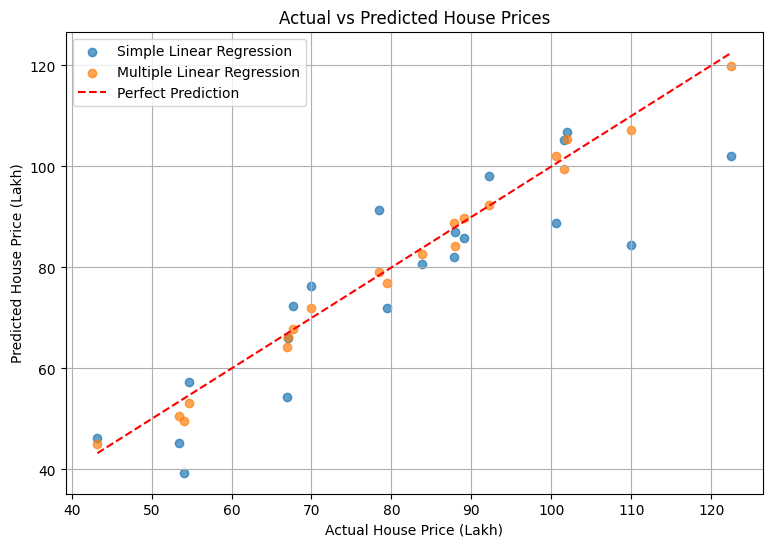

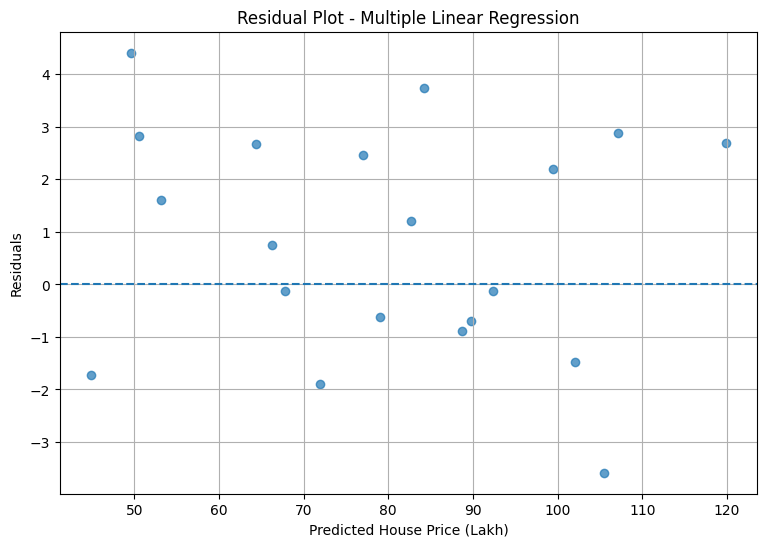

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create comparison DataFrame
results = pd.DataFrame({
    'Actual': y_test.values,
    'Simple Predicted': y_pred_simple,
    'Multiple Predicted': y_pred_multiple
})

# Actual vs Predicted Plot
plt.figure(figsize=(9, 6))

plt.scatter(
    results['Actual'],
    results['Simple Predicted'],
    label='Simple Linear Regression',
    alpha=0.7
)

plt.scatter(
    results['Actual'],
    results['Multiple Predicted'],
    label='Multiple Linear Regression',
    alpha=0.7
)

min_value = results['Actual'].min()
max_value = results['Actual'].max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual House Price (Lakh)')
plt.ylabel('Predicted House Price (Lakh)')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.grid(True)
plt.show()


# Residual Plot for Multiple Linear Regression
residuals = y_test.values - y_pred_multiple

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_multiple,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted House Price (Lakh)')
plt.ylabel('Residuals')
plt.title('Residual Plot - Multiple Linear Regression')
plt.grid(True)
plt.show()